In [15]:
!pip -q install sentence-transformers scikit-learn


In [14]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.feature_extraction.text import TfidfVectorizer


In [11]:
from google.colab import files
uploaded = files.upload()


Saving reduced_icecat_data_train_transformed.json to reduced_icecat_data_train_transformed.json


Load JSON into a DataFrame

In [16]:
FILENAME = "reduced_icecat_data_train_transformed.json"

with open(FILENAME, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

print("Shape:", df.shape)
df.head()


Shape: (31766, 46)


,ID,Brand,BrandInfo.BrandLocalName,BrandInfo.BrandLogo,BrandInfo.BrandName,BrandLogo,BrandPartCode,BulletPoints,Category.CategoryID,Category.Name.Language,...,ProductSeries.Language,ProductSeries.Value,BulletPoints.BulletPointsId,BulletPoints.Language,BulletPoints.Updated,BulletPoints.Values,VirtualCategory,SummaryDescription,pathlist_ids,pathlist_names
0,416603,DELL,,https://images.icecat.biz/img/brand/thumb/292_...,DELL,https://images.icecat.biz/img/brand/thumb/292_...,U8947,[],963,EN,...,None,None,None,None,None,None,None,None,2833>2557>963,Computers & Electronics>Batteries & Power Supp...
1,908983,Acer,,https://images.icecat.biz/img/brand/thumb/7_2e...,Acer,https://images.icecat.biz/img/brand/thumb/7_2e...,60.A46V1.009,[],2509,EN,...,None,None,None,None,None,None,None,None,2833>150>8355>2509,Computers & Electronics>Computers>Notebook Par...
2,955069,Toshiba,,https://images.icecat.biz/img/brand/thumb/2_b4...,Toshiba,https://images.icecat.biz/img/brand/thumb/2_b4...,SIC1016062LCD0,[],2509,EN,...,None,None,None,None,None,None,None,None,2833>150>8355>2509,Computers & Electronics>Computers>Notebook Par...
3,494327,Fujitsu,,https://images.icecat.biz/img/brand/thumb/15_b...,Fujitsu,https://images.icecat.biz/img/brand/thumb/15_b...,FSP:GB5H00Z00GBDPH,[],788,EN,...,None,None,None,None,None,None,None,None,2833>839>788,Computers & Electronics>Warranty & Support>War...
4,691783,Lenovo,,https://images.icecat.biz/img/brand/thumb/728_...,Lenovo,https://images.icecat.biz/img/brand/thumb/728_...,20BSS0EJ06,[],151,EN,...,EN,X,None,None,None,None,None,None,2833>150>151,Computers & Electronics>Computers>Notebooks


DATA ANALYSIS PHASE
5.1 Category Depth Inconsistency

In [17]:
def split_path(x):
    if pd.isna(x) or x is None:
        return []
    return [p.strip() for p in str(x).split(">") if p.strip()]

df["cat_path"] = df["pathlist_names"].apply(split_path)
df["cat_depth"] = df["cat_path"].apply(len)

depth_counts = df["cat_depth"].value_counts().sort_index()
depth_counts


,count
cat_depth,
3,18741
4,13025


Cell 6 (plot)



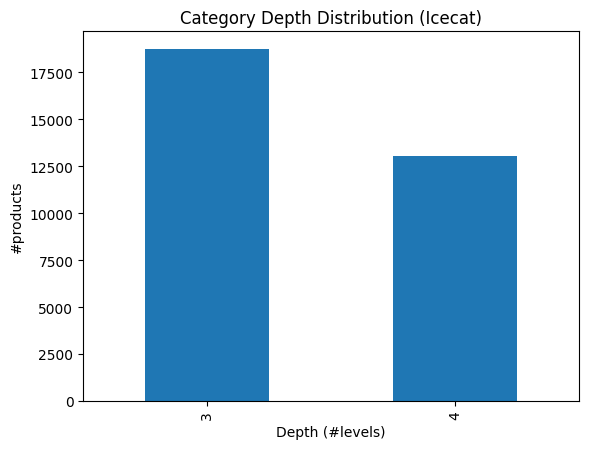

In [18]:
depth_counts.plot(kind="bar")
plt.title("Category Depth Distribution (Icecat)")
plt.xlabel("Depth (#levels)")
plt.ylabel("#products")
plt.show()


5.2 Standardize to 3 Category Levels

In [19]:
def to_3_levels(path):
    if len(path) == 0:
        return (None, None, None)
    if len(path) == 1:
        return (path[0], path[0], path[0])
    if len(path) == 2:
        return (path[0], path[1], path[1])

    return (path[0], path[1], path[-1])

df[["L1","L2","L3"]] = df["cat_path"].apply(lambda p: pd.Series(to_3_levels(p)))
df["std_category_3lvl"] = df["L1"] + " > " + df["L2"] + " > " + df["L3"]

df[["pathlist_names","std_category_3lvl"]].head(10)


,pathlist_names,std_category_3lvl
0,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
1,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
2,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
3,Computers & Electronics>Warranty & Support>War...,Computers & Electronics > Warranty & Support >...
4,Computers & Electronics>Computers>Notebooks,Computers & Electronics > Computers > Notebooks
5,Computers & Electronics>Computer Components>Sy...,Computers & Electronics > Computer Components ...
6,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
7,Computers & Electronics>Computer Cables>USB Ca...,Computers & Electronics > Computer Cables > US...
8,Computers & Electronics>Telecom & Navigation>S...,Computers & Electronics > Telecom & Navigation...
9,Computers & Electronics>Projectors>Projector A...,Computers & Electronics > Projectors > Project...


Cell 8 (validate all are 3 levels)

In [20]:
df["std_category_3lvl"].apply(lambda x: len(str(x).split(">"))).value_counts()


,count
std_category_3lvl,
3,31766


5.3 Product Distribution Analysis

In [23]:
std_counts = df["std_category_3lvl"].value_counts()
print("Unique standardized categories:", std_counts.size)
std_counts.head(10)


Unique standardized categories: 353


,count
std_category_3lvl,
Computers & Electronics > Computers > Notebook Spare Parts,6072
Computers & Electronics > Computers > Notebooks,5442
Computers & Electronics > Warranty & Support > Warranty & Support Extensions,1814
Computers & Electronics > Software > Software Licenses/Upgrades,1437
Computers & Electronics > Computers > PCs/Workstations,1425
Computers & Electronics > Printers & Scanners > Toner Cartridges,713
Computers & Electronics > Data Storage > Internal Hard Drives,531
Computers & Electronics > TVs & Monitors > TVs,530
Computers & Electronics > Data Input Devices > Keyboards,488


Cell 10 (plot imbalance)

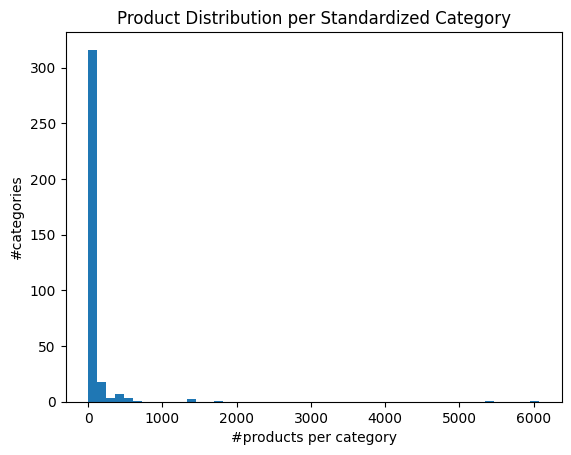

In [24]:
plt.hist(std_counts.values, bins=50)
plt.title("Product Distribution per Standardized Category")
plt.xlabel("#products per category")
plt.ylabel("#categories")
plt.show()


6) IMPLEMENTATION PHASE (Unsupervised ML)
6.1 Prepare Text (Remove category labels for learning)

In [25]:
df["text"] = (
    df["BrandInfo.BrandName"].fillna("") + " " +
    df["BrandPartCode"].fillna("")
).str.strip()

df_ml = df[df["text"].str.len() > 5].copy()
print("Rows used for ML:", len(df_ml))
df_ml[["ID","text"]].head()


Rows used for ML: 31766


,ID,text
0,416603,DELL U8947
1,908983,Acer 60.A46V1.009
2,955069,Toshiba SIC1016062LCD0
3,494327,Fujitsu FSP:GB5H00Z00GBDPH
4,691783,Lenovo 20BSS0EJ06


6.2 SBERT Embeddings

In [26]:
model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = model.encode(
    df_ml["text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)
embeddings = np.asarray(embeddings, dtype=np.float32)

print("Embeddings shape:", embeddings.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/497 [00:00<?, ?it/s]

Embeddings shape: (31766, 384)


6.3 K-Means Clustering

In [9]:
#k = 30
#kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
#df_ml["kmeans_cluster"] = kmeans.fit_predict(embeddings)

#df_ml["kmeans_cluster"].value_counts().head(10)


6.4 DBSCAN Clustering

In [27]:
dbscan = DBSCAN(eps=0.4, min_samples=10, metric="euclidean")
df_ml["dbscan_cluster"] = dbscan.fit_predict(embeddings)

df_ml["dbscan_cluster"].value_counts().head(10)


,count
dbscan_cluster,
-1,17230
3,1513
0,1402
8,1125
17,998
15,785
24,614
18,571
16,542


7) Regenerate Category Names (Auto-label clusters)

In [28]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

def label_clusters(texts, labels, top_n=5):
    vectorizer = TfidfVectorizer(stop_words="english")
    X = vectorizer.fit_transform(texts)
    terms = np.array(vectorizer.get_feature_names_out())

    names = {}
    for c in sorted(set(labels)):
        if c == -1:
            names[c] = "Noise"
            continue
        idx = np.where(labels == c)[0]
        if len(idx) == 0:
            names[c] = f"Cluster_{c}"
            continue
        scores = X[idx].mean(axis=0).A1
        top_terms = terms[scores.argsort()[-top_n:]][::-1]
        names[c] = ", ".join(top_terms)
    return names

cluster_names = label_clusters(
    df_ml["text"].tolist(),
    df_ml["dbscan_cluster"].values,
    top_n=5
)

df_ml["auto_category"] = df_ml["dbscan_cluster"].map(cluster_names)


cluster_names


{np.int64(-1): 'Noise',
 np.int64(0): 'toshiba, psktae, psktne, pscg6e, ps585e',
 np.int64(1): 'fsp, fujitsu, gb3s20z00ndf35, gd3463400dest4, gd33i3300dest1',
 np.int64(2): 'lenovo, len24, 20ljs03w00, 20ljs0mg02, 20lq0000uk',
 np.int64(3): 'lenovo, 59, 57, 40y8013, 40y7699',
 np.int64(4): 'power, alt28109a, alt28127a, alt28172a, alt28230a',
 np.int64(5): 'lenovo, fru42x5060, fru42w8292, fru42w7871, fru42t4911',
 np.int64(6): 'xerox, 016, 497k03140, 497k02941, 097n01524',
 np.int64(7): 'fujitsu, s26361, s26391, s26381, l100',
 np.int64(8): 'hp, sic1236893lcd0, sic1236938lcd0, sic1236948lcd0, sic1236952lcd0',
 np.int64(9): 'hp, h1k92a3, h7j34a5, h1k93a3, yzv',
 np.int64(10): '3m, 98044062390, 98044062135, 98044054900, 98044054074',
 np.int64(11): '55, acer, lk, 60, 002',
 np.int64(12): '890, dell, 10083, 9020, 10608',
 np.int64(13): 'asus, 10, 13gndo1ap041, 13gnrl2ap020, 13gnrm4ap010',
 np.int64(14): 'kaspersky, lab, kl4867xandq, kl4863xamfc, kl4863xapfs',
 np.int64(15): 'asus, 90, m0eay

“Clustering produces numeric groups that are not interpretable. To convert them into a usable taxonomy, I applied TF-IDF keyword extraction within each cluster and used the most representative terms as automatically generated category names.”

In [29]:
cluster_names


{np.int64(-1): 'Noise',
 np.int64(0): 'toshiba, psktae, psktne, pscg6e, ps585e',
 np.int64(1): 'fsp, fujitsu, gb3s20z00ndf35, gd3463400dest4, gd33i3300dest1',
 np.int64(2): 'lenovo, len24, 20ljs03w00, 20ljs0mg02, 20lq0000uk',
 np.int64(3): 'lenovo, 59, 57, 40y8013, 40y7699',
 np.int64(4): 'power, alt28109a, alt28127a, alt28172a, alt28230a',
 np.int64(5): 'lenovo, fru42x5060, fru42w8292, fru42w7871, fru42t4911',
 np.int64(6): 'xerox, 016, 497k03140, 497k02941, 097n01524',
 np.int64(7): 'fujitsu, s26361, s26391, s26381, l100',
 np.int64(8): 'hp, sic1236893lcd0, sic1236938lcd0, sic1236948lcd0, sic1236952lcd0',
 np.int64(9): 'hp, h1k92a3, h7j34a5, h1k93a3, yzv',
 np.int64(10): '3m, 98044062390, 98044062135, 98044054900, 98044054074',
 np.int64(11): '55, acer, lk, 60, 002',
 np.int64(12): '890, dell, 10083, 9020, 10608',
 np.int64(13): 'asus, 10, 13gndo1ap041, 13gnrl2ap020, 13gnrm4ap010',
 np.int64(14): 'kaspersky, lab, kl4867xandq, kl4863xamfc, kl4863xapfs',
 np.int64(15): 'asus, 90, m0eay

Cell 17 (View final generated categories)

In [31]:
df_ml[["text","kmeans_cluster","auto_category"]].head(15)


KeyError: "['kmeans_cluster'] not in index"

Cell 18 (Top generated categories by size)

In [32]:
df_ml["auto_category"].value_counts().head(15)


,count
auto_category,
Noise,17230
"lenovo, 59, 57, 40y8013, 40y7699",1513
"toshiba, psktae, psktne, pscg6e, ps585e",1402
"hp, sic1236893lcd0, sic1236938lcd0, sic1236948lcd0, sic1236952lcd0",1125
"hp, 001, b21, 171, 071",998
"asus, 90, m0eay0, m0na00, 0knb0",785
"hp, 7vh92pa, 7vw06ea, uw118e, 4ub62ea",614
"nx, acer, 002, 001, 004",571
"trend, micro, cm00872411, cm00872396, cm00872359",542


In [1]:
final_cols = [
    "ID",
    "std_category_3lvl",
    "text",
    "kmeans_cluster",
    "auto_category",
    "dbscan_cluster"
]

df_ml[final_cols].to_csv("icecat_taxonomy_results.csv", index=False)

from google.colab import files
files.download("icecat_taxonomy_results.csv")


NameError: name 'df_ml' is not defined